# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Matthew Calvario, Michael Mitchell, Carter Shaffer

**Date:** 11/09/26

In [1]:
!git clone https://github.com/Matthew-Calvario/L02-hedonic-pricing.git

Cloning into 'L02-hedonic-pricing'...
remote: Enumerating objects: 12, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 12 (delta 2), reused 0 (delta 0), pack-reused 8 (from 1)
Receiving objects: 100% (12/12), 255.81 KiB | 1.92 MiB/s, done.
Resolving deltas: 100% (2/2), done.



 Question 1. 

Shape: 


(16814, 19)

,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms
count,1.681400e+04,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000
mean,4.612332e+05,1879.941953,24.945878,167.852861,364.425122,38.298501,0.889021,1.558285,1980.469252,3.277983,2.317176
std,2.360833e+05,760.419008,102.066417,429.065832,286.454018,164.691471,0.596731,0.512055,33.339025,0.891240,0.827956
min,2.000000e+03,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1880.000000,0.000000,0.000000
25%,3.480000e+05,1320.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1959.000000,3.000000,2.000000
50%,4.165000e+05,1774.000000,0.000000,0.000000,420.000000,0.000000,1.000000,2.000000,1990.000000,3.000000,2.000000
75%,5.238065e+05,2352.000000,0.000000,0.000000,528.000000,0.000000,1.000000,2.000000,2006.000000,4.000000,3.000000
max,6.130000e+06,9510.000000,1212.000000,4000.000000,2816.000000,3664.000000,5.000000,3.000000,2021.000000,25.000000,8.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   sale_date                    16814 non-null  object
 1   sale_price                   16814 non-null  int64 
 2   house_square_feet            16814 non-null  int64 
 3   attic_finished_square_feet   16814 non-null  int64 
 4   basement_square_feet         16814 non-null  int64 
 5   attached_garage_square_feet  16814 non-null  int64 
 6   detached_garage_square_feet  16814 non-null  int64 
 7   fireplaces                   16814 non-null  int64 
 8   hvac_description             16807 non-null  object
 9   exterior                     16813 non-null  object
 10  interior                     16807 non-null  object
 11  stories                      16814 non-null  int64 
 12  roof_cover                   16806 non-null  object
 13  year_built                   16

None

,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


... (8 outputs left out)

(16768, 17)

<class 'pandas.core.frame.DataFrame'>
Index: 16768 entries, 0 to 16813
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   sale_date                    16768 non-null  object
 1   sale_price                   16768 non-null  int64 
 2   house_square_feet            16768 non-null  int64 
 3   attic_finished_square_feet   16768 non-null  int64 
 4   basement_square_feet         16768 non-null  int64 
 5   attached_garage_square_feet  16768 non-null  int64 
 6   detached_garage_square_feet  16768 non-null  int64 
 7   fireplaces                   16768 non-null  int64 
 8   hvac_description             16768 non-null  object
 9   exterior                     16768 non-null  object
 10  interior                     16768 non-null  object
 11  stories                      16768 non-null  int64 
 12  roof_cover                   16768 non-null  object
 13  year_built                   16768 n

None


 Distribution of sale prices to look for outliiers and overall shape 



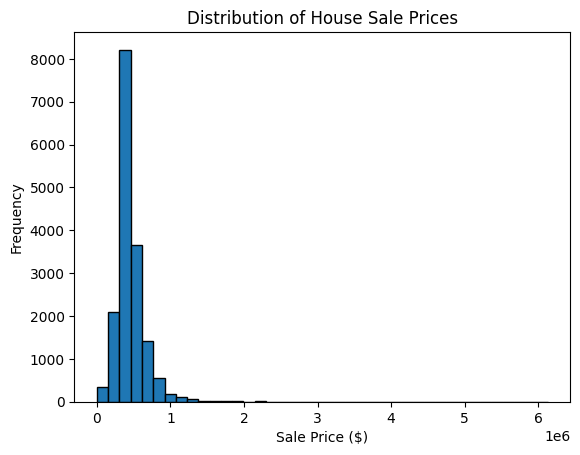


 Square footage vs. price since square footage is often an indicator 



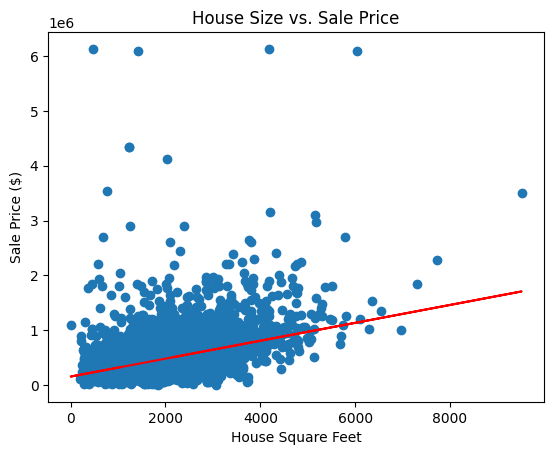


 Correlation heatmap to see if various features capture overlapping info 



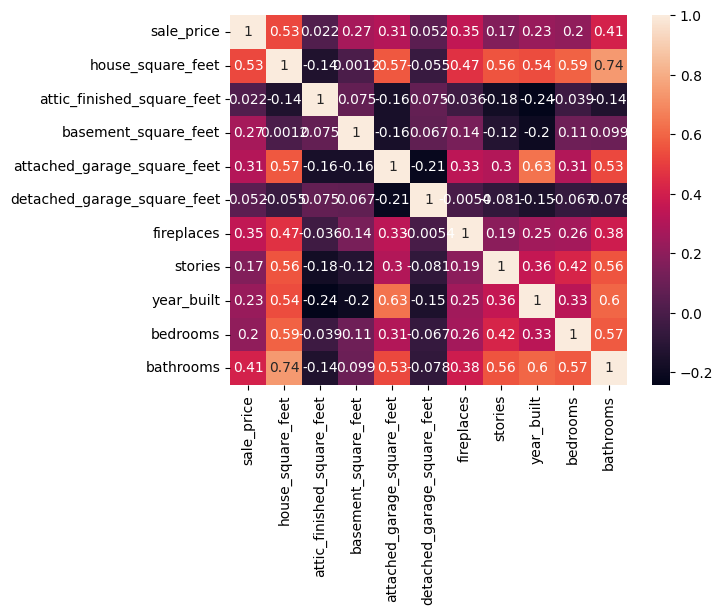


 Question 2. 

<class 'pandas.core.frame.DataFrame'>
Index: 16768 entries, 0 to 16813
Data columns (total 45 columns):
 #   Column                                   Non-Null Count  Dtype
---  ------                                   --------------  -----
 0   sale_date                                16768 non-null  int64
 1   sale_price                               16768 non-null  int64
 2   house_square_feet                        16768 non-null  int64
 3   attic_finished_square_feet               16768 non-null  int64
 4   basement_square_feet                     16768 non-null  int64
 5   attached_garage_square_feet              16768 non-null  int64
 6   detached_garage_square_feet              16768 non-null  int64
 7   fireplaces                               16768 non-null  int64
 8   stories                                  16768 non-null  int64
 9   year_built                               16768 non-null  int64
 10  bedrooms                                 16768 non-null  in

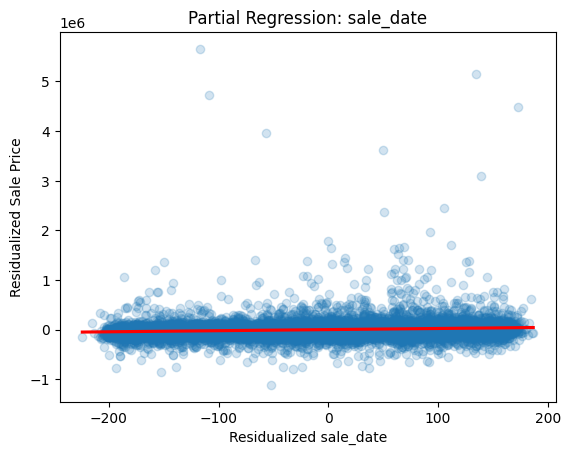


  From the partial regression plots, none of the 11 numeric columns appear to have
  any obvious nonlinearities--most follow approximately linear or weak adjusted relationships with sale price.
  However, some plots may require further investigation; for example, the bedrooms plot is quite tightly clustered,
  and while it is relatively representative of a negative linear slope, the presence of outliers may influence it. 
  


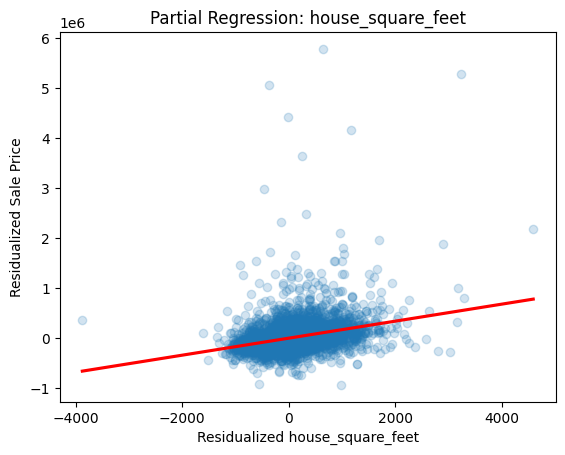


  From the partial regression plots, none of the 11 numeric columns appear to have
  any obvious nonlinearities--most follow approximately linear or weak adjusted relationships with sale price.
  However, some plots may require further investigation; for example, the bedrooms plot is quite tightly clustered,
  and while it is relatively representative of a negative linear slope, the presence of outliers may influence it. 
  


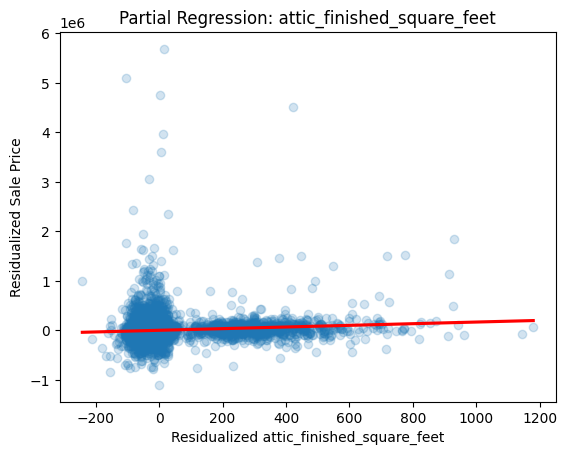


  From the partial regression plots, none of the 11 numeric columns appear to have
  any obvious nonlinearities--most follow approximately linear or weak adjusted relationships with sale price.
  However, some plots may require further investigation; for example, the bedrooms plot is quite tightly clustered,
  and while it is relatively representative of a negative linear slope, the presence of outliers may influence it. 
  


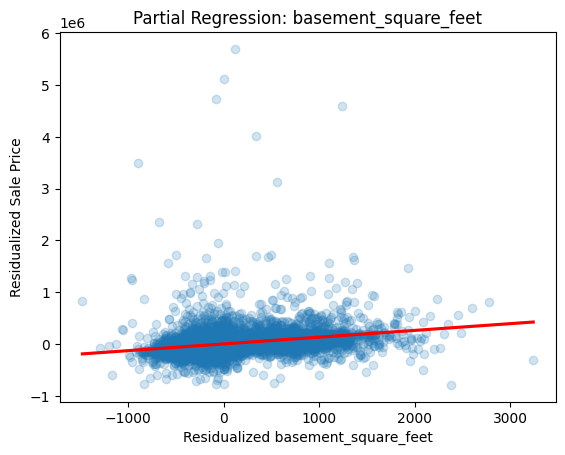


  From the partial regression plots, none of the 11 numeric columns appear to have
  any obvious nonlinearities--most follow approximately linear or weak adjusted relationships with sale price.
  However, some plots may require further investigation; for example, the bedrooms plot is quite tightly clustered,
  and while it is relatively representative of a negative linear slope, the presence of outliers may influence it. 
  


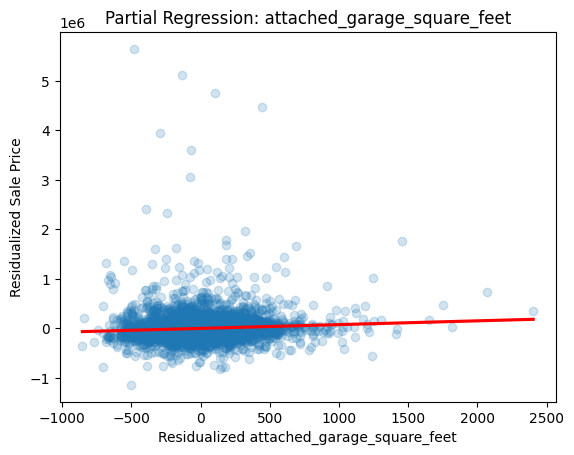


  From the partial regression plots, none of the 11 numeric columns appear to have
  any obvious nonlinearities--most follow approximately linear or weak adjusted relationships with sale price.
  However, some plots may require further investigation; for example, the bedrooms plot is quite tightly clustered,
  and while it is relatively representative of a negative linear slope, the presence of outliers may influence it. 
  


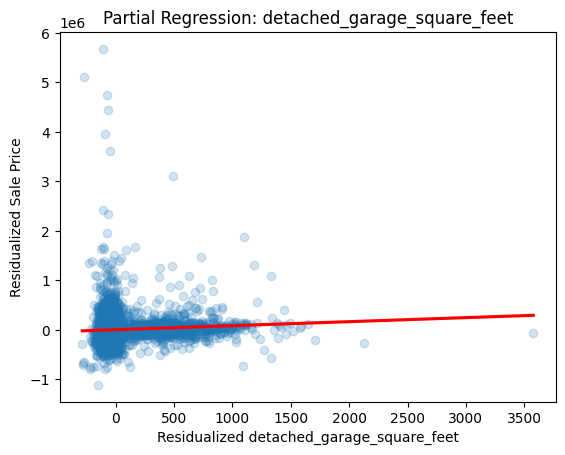


  From the partial regression plots, none of the 11 numeric columns appear to have
  any obvious nonlinearities--most follow approximately linear or weak adjusted relationships with sale price.
  However, some plots may require further investigation; for example, the bedrooms plot is quite tightly clustered,
  and while it is relatively representative of a negative linear slope, the presence of outliers may influence it. 
  


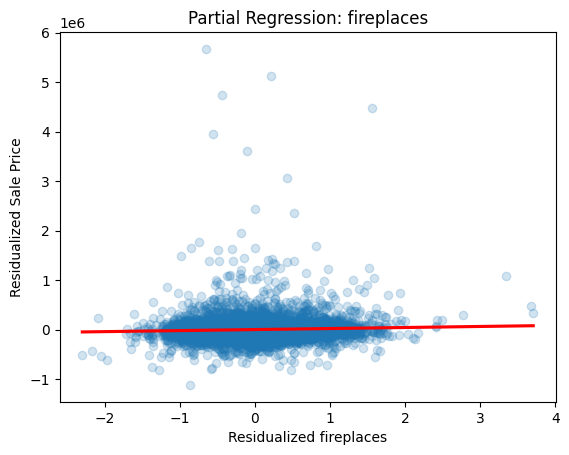


  From the partial regression plots, none of the 11 numeric columns appear to have
  any obvious nonlinearities--most follow approximately linear or weak adjusted relationships with sale price.
  However, some plots may require further investigation; for example, the bedrooms plot is quite tightly clustered,
  and while it is relatively representative of a negative linear slope, the presence of outliers may influence it. 
  


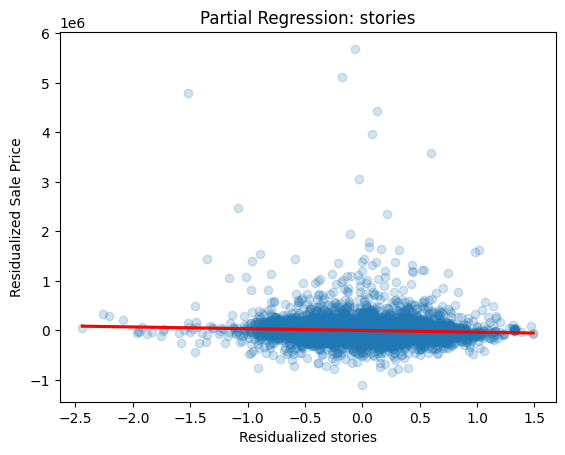


  From the partial regression plots, none of the 11 numeric columns appear to have
  any obvious nonlinearities--most follow approximately linear or weak adjusted relationships with sale price.
  However, some plots may require further investigation; for example, the bedrooms plot is quite tightly clustered,
  and while it is relatively representative of a negative linear slope, the presence of outliers may influence it. 
  


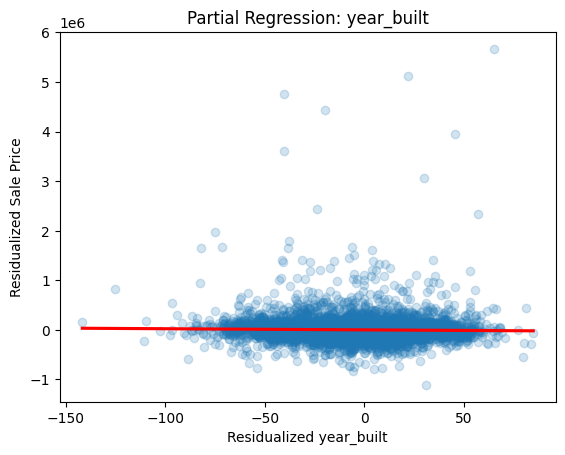


  From the partial regression plots, none of the 11 numeric columns appear to have
  any obvious nonlinearities--most follow approximately linear or weak adjusted relationships with sale price.
  However, some plots may require further investigation; for example, the bedrooms plot is quite tightly clustered,
  and while it is relatively representative of a negative linear slope, the presence of outliers may influence it. 
  


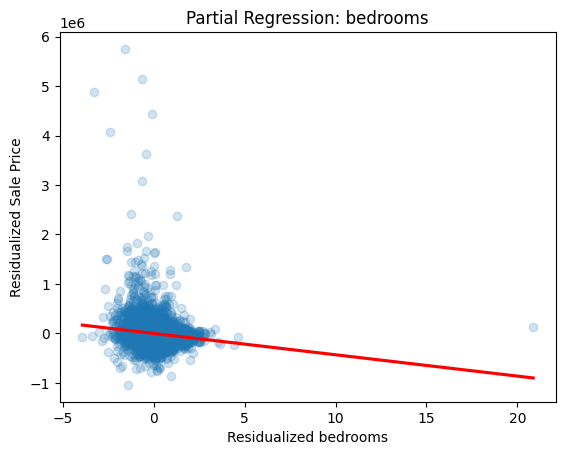


  From the partial regression plots, none of the 11 numeric columns appear to have
  any obvious nonlinearities--most follow approximately linear or weak adjusted relationships with sale price.
  However, some plots may require further investigation; for example, the bedrooms plot is quite tightly clustered,
  and while it is relatively representative of a negative linear slope, the presence of outliers may influence it. 
  


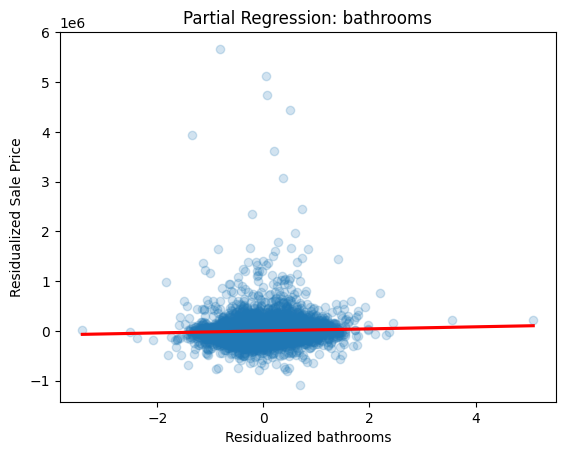


  From the partial regression plots, none of the 11 numeric columns appear to have
  any obvious nonlinearities--most follow approximately linear or weak adjusted relationships with sale price.
  However, some plots may require further investigation; for example, the bedrooms plot is quite tightly clustered,
  and while it is relatively representative of a negative linear slope, the presence of outliers may influence it. 
  

 Question 6. 

Complex Model
Train R^2: 0.4486504719158796
Train RMSE: 177833.08852406024
Test R^2: 0.42344163643248756
Test RMSE: 168582.25180830262

When incorporating an expanded model with polynomial terms and an IHS transformation, there was only a 
modest improvement in predictive performance compared to the baseline multiple regression model. Specifically, 
test R² increased from 0.420 to 0.423, while test RMSE decreased from $169,106 to $168,582. Since the partial 
regression plots showed no strong evidence of nonlinear relationships for most numerical fe

In [31]:
# Your Phase 1 solution to the problem goes here.

# Q1.

print("\n Question 1. \n")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('L02-hedonic-pricing/data/pierce_county_house_sales.csv')

# Basic EDA and Visualizations
print("Shape: ")
display(df.shape)
display(df.describe())
# Fields vary significantly in magnitude of values; scaling will most likely be done

display(df.info())
display(df.head())


# Check for NULL values and Null value percentages
display((df.isna().sum()))
display(((df.isna().sum()) / df.shape[0]) * 100)

# Impute fields with <5% null values (median if numeric, with mode if string/boolean)
df['hvac_description'] = df['hvac_description'].fillna(df['hvac_description'].mode().iloc[0])
df['exterior'] = df['exterior'].fillna(df['exterior'].mode().iloc[0])
df['interior'] = df['interior'].fillna(df['interior'].mode().iloc[0])
df['roof_cover'] = df['roof_cover'].fillna(df['roof_cover'].mode().iloc[0])

# (Improve efficiency/logic of imputation for Phase 2)

# Drop Columns with >50% null values

for i in df:
  if ((df[i].isna().sum()) / df.shape[0]) * 100 > 50:
    df = df.drop(columns = [i])

# Check for duplicated values (drop if present)
display(df.duplicated().sum())
df = df.drop_duplicates()

# Verify Cleaning:
print("\n CLEANED DATAFRAME \n")
print("\n Remaining Null Values per column \n")
display(df.isna().sum())

print("\n Remaining duplicated rows: \n")
display(df.duplicated().sum())

print("\n Shape and Info Cleaned \n")
display(df.shape)
display(df.info())

# Visualizations

print("\n Distribution of sale prices to look for outliiers and overall shape \n")
plt.hist(df['sale_price'], bins=40, edgecolor='black')
plt.xlabel('Sale Price ($)')
plt.ylabel('Frequency')
plt.title('Distribution of House Sale Prices')
plt.show()

print("\n Square footage vs. price since square footage is often an indicator \n")
plt.scatter(df['house_square_feet'], df['sale_price'])

#linear regression line to identify preliminary visual trends
x = df['house_square_feet']
y = df['sale_price']
m, b = np.polyfit(x, y, 1)
plt.plot(x, m*x + b, color = 'red')

plt.xlabel('House Square Feet')
plt.ylabel('Sale Price ($)')
plt.title('House Size vs. Sale Price')
plt.show()

print("\n Correlation heatmap to see if various features capture overlapping info \n")
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

# A few relationships appear relatively strong:
# - House Square Footage vs. Sale Price (0.53)
# - Bathrooms vs. Sale Price (0.41)
# - Fireplaces vs. Sale price (0.35)
# - House Square Footage vs. Bathrooms (0.74)
# - Year Built vs. Attached Garage Square Footage (0.63)
# - Year Built vs. Bathrooms (0.60)

# Q2.

print("\n Question 2. \n")

# One-hot encode the nominal variables:
nominal_cols = ['hvac_description','exterior', 'interior', 'roof_cover', 'utility_sewer']

df = pd.get_dummies(df, columns=nominal_cols, drop_first=True, dtype=int)

# convert sale_date to numeric days to capture temporal trends in housing prices for regression
df['sale_date'] = pd.to_datetime(df['sale_date'])
df['sale_date'] = (df['sale_date']-df['sale_date'].min()).dt.days

# Verify
df.info()
df.head()

# Q3.

print("\n Question 3. \n")

from sklearn.model_selection import train_test_split

X = df.drop(columns=['sale_price'])
y = df['sale_price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# Q4.

print("\n Question 4. \n")

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Model 1: Square Footage Only
model1 = LinearRegression()
model1.fit(X_train[['house_square_feet']], y_train)

y_train_pred1 = model1.predict(X_train[['house_square_feet']])
y_test_pred1 = model1.predict(X_test[['house_square_feet']])

print("Model 1")
print("Train R^2:", r2_score(y_train, y_train_pred1))
print("Train RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred1)))
print("Test R_2:", r2_score(y_test, y_test_pred1))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred1)))

# Model 2: Square Footage, Bedrooms, Bathrooms

features2 = ['house_square_feet', 'bedrooms', 'bathrooms']

model2 = LinearRegression()
model2.fit(X_train[features2], y_train)

y_train_pred2 = model2.predict(X_train[features2])
y_test_pred2 = model2.predict(X_test[features2])

print("Model 2")
print("Train R^2:", r2_score(y_train, y_train_pred2))
print("Train RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred2)))
print("Test R_2:", r2_score(y_test, y_test_pred2))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred2)))

# Model 3: All Predictors

model3 = LinearRegression()
model3.fit(X_train, y_train)

y_train_pred3 = model3.predict(X_train)
y_test_pred3 = model3.predict(X_test)

print("Model 2")
print("Train R^2:", r2_score(y_train, y_train_pred3))
print("Train RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred3)))
print("Test R_2:", r2_score(y_test, y_test_pred3))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred3)))

print("""
Looking at the respective R^2 and RMSE values, the third model--which had all
predictors-- performed the best on the test set, with about 42.0% explained by its regression.
Compared to models 1 and 2, it reduced testing RMSE by approximately $20,541.
""")

# Q5.

print("\n Question 5. \n")

numeric_cols = [
    'sale_date', 'house_square_feet',
    'attic_finished_square_feet', 'basement_square_feet',
    'attached_garage_square_feet', 'detached_garage_square_feet',
    'fireplaces', 'stories', 'year_built',
    'bedrooms', 'bathrooms'
]

for col in numeric_cols:

  # all other predictors
  other_cols = X_train.drop(columns=[col])

  # Remove effect of other predictos from sale price
  model_y = LinearRegression()
  model_y.fit(other_cols, y_train)
  residual_y = y_train - model_y.predict(other_cols)

  # Remove the effect of other predictors from the selected feature
  model_x = LinearRegression()
  model_x.fit(other_cols, X_train[col])
  residual_x = X_train[col] - model_x.predict(other_cols)

  # Using Seaborn ot create Partial Regresion plot

  sns.regplot(x=residual_x, y=residual_y,
        scatter_kws={'alpha': 0.2},
        line_kws={'color': 'red'},
        ci=None)

  plt.title(f'Partial Regression: {col}')
  plt.xlabel(f'Residualized {col}')
  plt.ylabel('Residualized Sale Price')
  plt.show()

  print("""
  From the partial regression plots, none of the 11 numeric columns appear to have
  any obvious nonlinearities--most follow approximately linear or weak adjusted relationships with sale price.
  However, some plots may require further investigation; for example, the bedrooms plot is quite tightly clustered,
  and while it is relatively representative of a negative linear slope, the presence of outliers may influence it.
  """)

# Q6.

print("\n Question 6. \n")

# Introducing Interactions

from sklearn.preprocessing import PolynomialFeatures

small = X_train[['house_square_feet', 'bathrooms']]

expander = PolynomialFeatures(degree=2, include_bias=False)
expanded_features = expander.fit_transform(small)

# Convert back to DataFrame
expanded_df = pd.DataFrame(
    expanded_features,
    columns = expander.get_feature_names_out(),
    index=X_train.index
)

# Add Features to original training set
X_train_complex = X_train.copy()

X_train_complex = pd.concat([
    X_train_complex,
    expanded_df.iloc[:, 2:]
], axis=1)

# IHS Transformation
X_train_complex['basement_ihs'] = np.arcsinh(
    X_train['basement_square_feet']
)

# Transformation for Test Data
small_test = X_test[['house_square_feet', 'bathrooms']]
expanded_test = expander.transform(small_test)
expanded_test_df = pd.DataFrame(
    expanded_test,
    columns=expander.get_feature_names_out(),
    index=X_test.index
)

X_test_complex = pd.concat([
    X_test,
    expanded_test_df.iloc[:, 2:]
], axis=1)

X_test_complex['basement_ihs'] = np.arcsinh(
    X_test['basement_square_feet']
)

#Fit Complex Regression Model
complex_model = LinearRegression()
complex_model.fit(X_train_complex, y_train)

# Predictions and Evaluations
y_train_complex = complex_model.predict(X_train_complex)
y_test_complex = complex_model.predict(X_test_complex)

print("Complex Model")
print("Train R^2:", r2_score(y_train, y_train_complex))
print("Train RMSE:", np.sqrt(mean_squared_error(y_train, y_train_complex)))

print("Test R^2:", r2_score(y_test, y_test_complex))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_test_complex)))

print("""
When incorporating an expanded model with polynomial terms and an IHS transformation, there was only a
modest improvement in predictive performance compared to the baseline multiple regression model. Specifically,
test R² increased from 0.420 to 0.423, while test RMSE decreased from $169,106 to $168,582. Since the partial
regression plots showed no strong evidence of nonlinear relationships for most numerical features, it makes sense
that the additional nonlinear terms contributed relatively little predictive information beyond the original housing
characteristics.
""")

# Q7.

print("\n Question 7. \n")

# Q8.

print("\n Question 8. \n")



## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]